# 01. EDA і стартові перевірки

Крок 5 плану проєкту A (Hillstrom Email Marketing, 64 000 клієнтів, 3 групи).
Що робимо: підключаємось до PostgreSQL, звіряємо цифри з SQL, дивимось на розподіл `spend`,
перевіряємо SRM (чи рівні групи) і баланс ковариат (чи схожі групи до листа).

Формальні тести тут лише діагностичні: вони перевіряють, чи коректна рандомізація. Основні A/B-тести (гіпотези H1–H3) будуть у кроці 6.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sqlalchemy import create_engine

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from load_data import URI  # reads DATABASE_URI from .env

sns.set_theme(style="whitegrid")
ORDER = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]  # control first

engine = create_engine(URI.replace("postgresql://", "postgresql+psycopg2://", 1))
df = pd.read_sql("""
    SELECT c.*, a.segment, o.visit, o.conversion, o.spend
    FROM customers c
    JOIN assignments a USING (customer_id)
    JOIN outcomes   o USING (customer_id)
""", engine)
df["segment"] = pd.Categorical(df["segment"], categories=ORDER, ordered=True)
for col in ["history", "spend"]:
    df[col] = df[col].astype(float)
print(df.shape)
df.head()

(64000, 13)


,customer_id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,1,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,2,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,3,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,4,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,5,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## 1. Звірка з SQL

Рахуємо pandas-ом ті самі цифри, що дав `sql/04_conversion_by_group.sql`, і порівнюємо їх із `results/04_conversion_by_group.csv`.

In [2]:
g = df.groupby("segment", observed=True).agg(n=("customer_id", "size"),
                                              visits=("visit", "sum"),
                                              buyers=("conversion", "sum"))
g["visit_rate_pct"] = (100 * g.visits / g.n).round(2)
g["conversion_rate_pct"] = (100 * g.buyers / g.n).round(3)

sql = pd.read_csv(ROOT / "results" / "04_conversion_by_group.csv").set_index("segment").loc[ORDER]
for col in ["n", "visits", "buyers", "visit_rate_pct", "conversion_rate_pct"]:
    assert np.allclose(g[col].astype(float), sql[col].astype(float)), col
print("Python == SQL for n, visits, buyers, visit_rate, conversion_rate")
g

Python == SQL for n, visits, buyers, visit_rate, conversion_rate


,n,visits,buyers,visit_rate_pct,conversion_rate_pct
segment,,,,,
No E-Mail,21306,2262,122,10.62,0.573
Mens E-Mail,21307,3894,267,18.28,1.253
Womens E-Mail,21387,3238,189,15.14,0.884


## 2. Розподіл `spend`

`spend` сильно зміщений: майже всі нулі. Викиди за IQR **не видаляємо**: великі покупки в цих даних і є сигнал.

In [3]:
s = df["spend"]
pos = s[s > 0]
print(f"Zeros: {(s == 0).mean():.2%}   buyers: {len(pos)}   max: {s.max():.2f}")
print(f"Mean per customer: {s.mean():.4f}")
print(f"Buyers only: mean {pos.mean():.2f}, median {pos.median():.2f}, skew {stats.skew(pos):.2f}")
q1, q3 = pos.quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR rule would flag {(pos > upper).sum()} of {len(pos)} buyers above {upper:.2f} (we keep them)")
pos.describe().round(2)

Zeros: 99.10%   buyers: 578   max: 499.00
Mean per customer: 1.0509
Buyers only: mean 116.36, median 80.80, skew 1.76
IQR rule would flag 39 of 578 buyers above 334.97 (we keep them)


count    578.00
mean     116.36
std      107.87
min       29.99
25%       32.27
50%       80.80
75%      153.35
max      499.00
Name: spend, dtype: float64

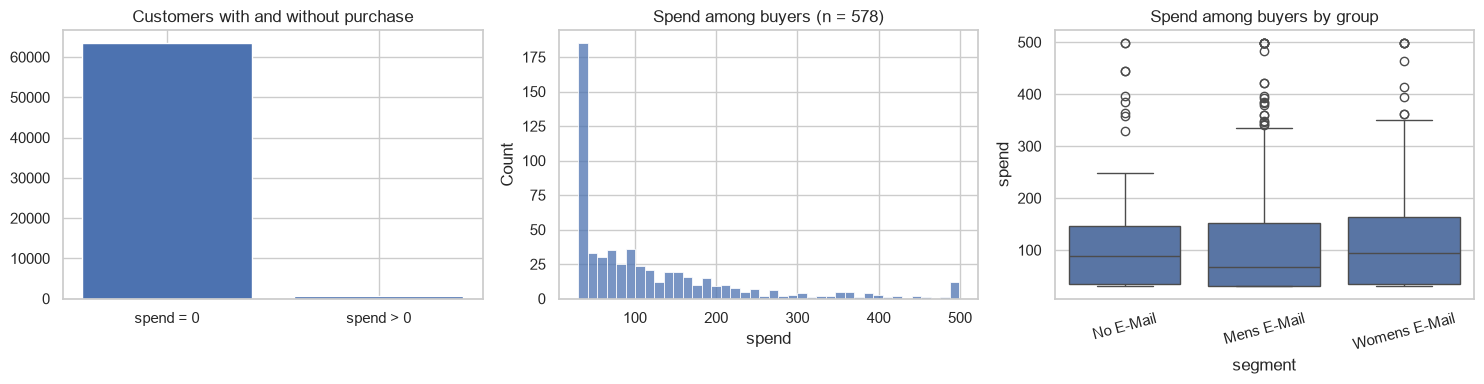

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(["spend = 0", "spend > 0"], [(s == 0).sum(), (s > 0).sum()])
ax[0].set_title("Customers with and without purchase")
sns.histplot(pos, bins=40, ax=ax[1])
ax[1].set_title("Spend among buyers (n = %d)" % len(pos))
sns.boxplot(data=df[df.spend > 0], x="segment", y="spend", order=ORDER, ax=ax[2])
ax[2].set_title("Spend among buyers by group")
ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 3. SRM-тест (sample ratio mismatch)

H0: клієнти розподілені по групах в пропорції 1/3 : 1/3 : 1/3. Chi-square на очікувані частки; зазвичай SRM вважають проблемою при p < 0,001.

In [5]:
observed = g["n"].reindex(ORDER).to_numpy()
expected = np.full(3, observed.sum() / 3)
chi2, p_srm = stats.chisquare(observed, expected)
print(dict(zip(ORDER, observed)), "expected each:", round(expected[0], 1))
print(f"chi2 = {chi2:.4f}, df = 2, p = {p_srm:.4f}")
print("SRM detected (p < 0.001)" if p_srm < 0.001 else "No SRM: group sizes are consistent with equal allocation")

{'No E-Mail': np.int64(21306), 'Mens E-Mail': np.int64(21307), 'Womens E-Mail': np.int64(21387)} expected each: 21333.3
chi2 = 0.2025, df = 2, p = 0.9037
No SRM: group sizes are consistent with equal allocation


## 4. Баланс ковариат

Рандомізація має дати подібні розподіли. Для числових змінних (`recency`, `history`) рахуємо стандартизовану різницю середніх (SMD, за модулем, для кожної пари груп), ANOVA і Kruskal-Wallis. SMD < 0,1 вважається незначною нерівновагою.
Для категоріальних: chi-square на таблиці «група × рівень» і Cramér's V.

In [6]:
def smd(a, b):
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (a.mean() - b.mean()) / pooled


rows = []
for var in ["recency", "history"]:
    parts = {k: df.loc[df.segment == k, var] for k in ORDER}
    max_smd = max(abs(smd(parts[a], parts[b])) for a, b in combinations(ORDER, 2))
    rows.append({"variable": var, "type": "numeric",
                 "stat": "max |SMD| = %.4f" % max_smd,
                 "effect": max_smd,
                 "p_value": stats.f_oneway(*parts.values()).pvalue,
                 "p_kruskal": stats.kruskal(*parts.values()).pvalue})

for var in ["newbie", "channel", "zip_code", "history_segment", "mens", "womens"]:
    ct = pd.crosstab(df["segment"], df[var]).reindex(ORDER)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    rows.append({"variable": var, "type": "categorical",
                 "stat": "chi2 = %.2f, df = %d, V = %.4f" % (chi2, dof, v),
                 "effect": v, "p_value": p, "p_kruskal": np.nan})

balance = pd.DataFrame(rows)
balance["p_holm"] = multipletests(balance["p_value"], method="holm")[1]
for col in ["p_value", "p_kruskal", "p_holm"]:
    balance[col] = balance[col].round(4)
balance[["variable", "type", "stat", "p_value", "p_kruskal", "p_holm"]]

,variable,type,stat,p_value,p_kruskal,p_holm
0,recency,numeric,max |SMD| = 0.0068,0.7631,0.7941,1.0
1,history,numeric,max |SMD| = 0.0076,0.6980,0.6669,1.0
2,newbie,categorical,"chi2 = 0.14, df = 2, V = 0.0015",0.9339,NaN,1.0
3,channel,categorical,"chi2 = 3.63, df = 4, V = 0.0053",0.4580,NaN,1.0
4,zip_code,categorical,"chi2 = 2.87, df = 4, V = 0.0047",0.5795,NaN,1.0
5,history_segment,categorical,"chi2 = 13.15, df = 12, V = 0.0101",0.3580,NaN,1.0
6,mens,categorical,"chi2 = 0.80, df = 2, V = 0.0035",0.6717,NaN,1.0
7,womens,categorical,"chi2 = 0.63, df = 2, V = 0.0031",0.7289,NaN,1.0


In [7]:
print("Variables with raw p < 0.05:", list(balance.loc[balance.p_value < 0.05, "variable"]))
print("Variables with Holm-adjusted p < 0.05:", list(balance.loc[balance.p_holm < 0.05, "variable"]))
print("Largest effect (SMD or Cramer's V):", round(balance["effect"].max(), 4), "for", balance.loc[balance["effect"].idxmax(), "variable"])
print("Expected number of raw p < 0.05 by chance among %d tests: %.1f" % (len(balance), 0.05 * len(balance)))

Variables with raw p < 0.05: []
Variables with Holm-adjusted p < 0.05: []
Largest effect (SMD or Cramer's V): 0.0101 for history_segment
Expected number of raw p < 0.05 by chance among 8 tests: 0.4


## Підсумок

- **Звірка з SQL:** Python дає ті самі `n`, візити, покупки й частки в усіх трьох групах.
- **`spend`:** 99,10 % нулів, 578 покупців; серед покупців середнє 116,36 проти медіани 80,80, асиметрія 1,76 (довгий правий хвіст, максимум 499). За правилом IQR 39 покупців були б «викидами», але ми їх залишаємо.
- **SRM:** chi2 = 0,2025, df = 2, p = 0,9037. Розміри груп узгоджуються з рівним розподілом, SRM немає.
- **Баланс ковариат:** максимальна |SMD| 0,0076 (`history`), максимальний Cramér's V 0,0101 (`history_segment`), усі сирі p від 0,358 до 0,934, після поправки Holm усі p = 1. Жодна змінна не розрізняє групи, тож рандомізація виглядає коректною.

**Висновок:** підстав сумніватись у рандомізації немає; можна переходити до основних тестів (крок 6). Через великий хвіст `spend` для нього знадобляться Welch, Mann-Whitney і bootstrap.

## 5. Збереження

Таблицю балансу зберігаємо в `results/` для README та кроку 6.

In [8]:
out = ROOT / "results" / "eda_balance_checks.csv"
balance.to_csv(out, index=False)
print("saved", out.relative_to(ROOT))

saved results\eda_balance_checks.csv
